# Comparative Analysis of Clustering Algorithms

## Project Overview

This study evaluates and compares four unsupervised clustering algorithms: **K-Means, DBSCAN, HDBSCAN, and Gaussian Mixture Models (GMM)**.

The experiments are conducted on **five synthetic datasets** and **three real-world datasets**, each representing different data characteristics, including cluster geometry, density variation, dimensionality, and overlapping distributions.

The objective is to investigate how these characteristics influence clustering performance and identify the strengths, limitations, and suitable applications of each algorithm.

Each dataset follows a consistent experimental workflow:

1. Data preparation and preprocessing
2. Application of the four clustering algorithms
3. Evaluation using Adjusted Rand Index (ARI), Normalized Mutual Information (NMI), Silhouette Score, and Davies–Bouldin Index (DBI)
4. Visualization and interpretation of the clustering results

Ground-truth labels are used solely for external evaluation and are not provided as input features to the clustering algorithms.

## 1. Evaluation Metrics

Four evaluation metrics are used to assess clustering performance from both external and internal perspectives.

| Metric | Evaluation Type | Interpretation | Preferred Direction |
|---|---|---|---|
| **Adjusted Rand Index (ARI)** | External | Measures agreement between predicted clusters and ground-truth labels, adjusted for chance. | Higher (1 = perfect) |
| **Normalized Mutual Information (NMI)** | External | Measures the amount of information shared between predicted clusters and ground-truth labels. | Higher (1 = perfect) |
| **Silhouette Score** | Internal | Evaluates how closely observations are grouped within their clusters relative to other clusters. | Higher (maximum = 1) |
| **Davies–Bouldin Index (DBI)** | Internal | Measures within-cluster dispersion relative to separation between cluster centroids. | Lower (minimum = 0) |

### Why Use Both External and Internal Metrics?

**ARI and NMI** evaluate how closely the predicted clusters correspond to known class labels. However, these labels may not necessarily represent the natural clustering structure of the data.

**Silhouette Score and DBI** evaluate clustering quality without requiring ground-truth labels. They emphasize cluster cohesion and separation, making them useful for identifying compact and well-separated clusters.

However, these internal metrics may be misleading for non-convex structures, such as concentric circles, where correctly identified clusters may still receive poor scores.

Using both types of metrics provides a more comprehensive evaluation of clustering performance.

### Handling Noise Points

DBSCAN and HDBSCAN may classify observations as noise (`-1`).

For consistency:

- ARI and NMI are calculated using all observations, including noise-labeled points.
- Silhouette Score and DBI are calculated using only non-noise observations.
- Noise percentage is reported separately.
- Internal metrics are recorded as `NaN` when fewer than two valid clusters remain or the metric is otherwise undefined.

### Experimental Considerations

K-Means and GMM require the number of clusters to be specified, whereas DBSCAN and HDBSCAN determine the number of clusters based on density characteristics. In this study, K-Means and GMM use the number of known classes to provide a consistent reference for comparison.

Some density-based parameter configurations were selected using exploratory comparisons with ground-truth labels. Consequently, the experiments should not be interpreted as a fully label-independent hyperparameter selection study.

All algorithms are evaluated using the same four metrics, while differences in their underlying assumptions are considered when interpreting the results.

In [31]:

# Libraries and dependencies
import time
import io
import zipfile
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.datasets import make_blobs, make_moons, make_circles
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.cluster import KMeans, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score,
    silhouette_score,
    davies_bouldin_score
)

import hdbscan


# Reproducibility settings
RANDOM_STATE = 42
ALGORITHMS = ['K-Means', 'DBSCAN', 'HDBSCAN', 'GMM']


# Calculate clustering evaluation metrics
def evaluate(X, y_true, labels, algorithm, runtime):
    labels = np.asarray(labels)
    keep = labels != -1

    clusters = len(set(labels) - {-1})
    silhouette, dbi = np.nan, np.nan

    n_valid = keep.sum()

    if 2 <= clusters < n_valid:
        X_valid = X[keep]
        labels_valid = labels[keep]

        silhouette = silhouette_score(
            X_valid,
            labels_valid,
            sample_size=min(2000, n_valid),
            random_state=RANDOM_STATE
        )

        dbi = davies_bouldin_score(
            X_valid,
            labels_valid
        )

    return {
        'Algorithm': algorithm,
        'ARI': adjusted_rand_score(y_true, labels),
        'NMI': normalized_mutual_info_score(y_true, labels),
        'Silhouette': silhouette,
        'DBI': dbi,
        'Clusters': clusters,
        'Noise (%)': 100 * np.mean(~keep),
        'Runtime (s)': runtime
    }


# Run K-Means, DBSCAN, HDBSCAN and GMM
def run_four(X, y, k, dbscan_eps,
             hdbscan_min_size=15,
             hdbscan_min_samples=5,
             dbscan_min_samples=5):

    models = [
        (
            'K-Means',
            KMeans(
                n_clusters=k,
                init='k-means++',
                n_init=10,
                random_state=RANDOM_STATE
            )
        ),
        (
            'DBSCAN',
            DBSCAN(
                eps=dbscan_eps,
                min_samples=dbscan_min_samples
            )
        ),
        (
            'HDBSCAN',
            hdbscan.HDBSCAN(
                min_cluster_size=hdbscan_min_size,
                min_samples=hdbscan_min_samples
            )
        ),
        (
            'GMM',
            GaussianMixture(
                n_components=k,
                covariance_type='full',
                reg_covar=1e-5,
                n_init=3,
                random_state=RANDOM_STATE,
                max_iter=300
            )
        )
    ]

    results = []
    predictions = {}

    for name, model in models:
        start = time.perf_counter()
        labels = model.fit_predict(X)
        elapsed = time.perf_counter() - start

        predictions[name] = labels
        results.append(
            evaluate(X, y, labels, name, elapsed)
        )

    return pd.DataFrame(results), predictions


# Visualize ground truth and predicted clusters
def plot_clusters(X_2d, y_true, predictions, title, pca_used=False):

    items = [
        ('True Labels', LabelEncoder().fit_transform(y_true))
    ] + list(predictions.items())

    fig, axes = plt.subplots(
        1, len(items),
        figsize=(19, 3.5)
    )

    for ax, (name, labels) in zip(axes, items):

        labels = np.asarray(labels)
        noise = labels == -1

        ax.scatter(
            X_2d[~noise, 0],
            X_2d[~noise, 1],
            c=labels[~noise],
            cmap='tab10',
            s=8,
            alpha=0.65,
            rasterized=True
        )

        if noise.any():
            ax.scatter(
                X_2d[noise, 0],
                X_2d[noise, 1],
                c='lightgrey',
                s=8,
                alpha=0.65,
                rasterized=True
            )

        ax.set_title(name)

        if pca_used:
            ax.set_xlabel('PC1')
            ax.set_ylabel('PC2')
        else:
            ax.set_xlabel('Feature 1')
            ax.set_ylabel('Feature 2')

    fig.suptitle(title, fontsize=13)
    plt.tight_layout()
    plt.show()


# Display results and clustering visualizations
def show_experiment(name, X, y, k, eps,
                    min_size=15,
                    min_samples=5,
                    dbscan_min_samples=5,
                    X_plot=None):

    table, predictions = run_four(
        X, y, k, eps,
        min_size, min_samples,
        dbscan_min_samples
    )

    table.insert(0, 'Dataset', name)

    print(
        f'\n{name}: {X.shape[0]:,} observations '
        f'× {X.shape[1]} features'
    )

    display(table.round(4))

    pca_used = X.shape[1] > 2

    if X_plot is None:
        if pca_used:
            X_plot = PCA(
                n_components=2,
                random_state=RANDOM_STATE
            ).fit_transform(X)
        else:
            X_plot = X

    plot_clusters(
        X_plot, y, predictions,
        name, pca_used=pca_used
    )

    return table, predictions


# Store results for final comparison
all_tables = []


## 2. Synthetic Datasets

Five synthetic datasets are used to evaluate how different cluster characteristics affect the performance of K-Means, DBSCAN, HDBSCAN, and GMM.

| Dataset | Characteristics | Purpose |
|---|---|---|
| **Gaussian Blobs** | Compact, well-separated clusters | Evaluate performance on simple cluster structures |
| **Two Moons** | Two interlocking, non-convex clusters | Examine the ability to identify irregular cluster shapes |
| **Concentric Circles** | Two nested circular clusters | Evaluate performance on non-convex, overlapping-centroid structures |
| **Varying Density** | Clusters with different densities | Examine sensitivity to density variation, particularly for DBSCAN and HDBSCAN |
| **Elliptical Gaussian Clusters** | Elongated, elliptical clusters | Evaluate whether GMM benefits from modeling cluster covariance |

Each dataset contains **600 observations** and is generated using a fixed random seed to ensure reproducibility.

All four algorithms are evaluated using the same metrics, followed by visual comparisons and an analysis of their performance.


Gaussian Blobs: 600 observations × 2 features


,Dataset,Algorithm,ARI,NMI,Silhouette,DBI,Clusters,Noise (%),Runtime (s)
0,Gaussian Blobs,K-Means,1.0000,1.0000,0.8903,0.1549,3,0.0000,0.0316
1,Gaussian Blobs,DBSCAN,0.9648,0.9427,0.8950,0.1492,3,2.3333,0.0035
2,Gaussian Blobs,HDBSCAN,1.0000,1.0000,0.8903,0.1549,3,0.0000,0.0083
3,Gaussian Blobs,GMM,1.0000,1.0000,0.8903,0.1549,3,0.0000,0.0209


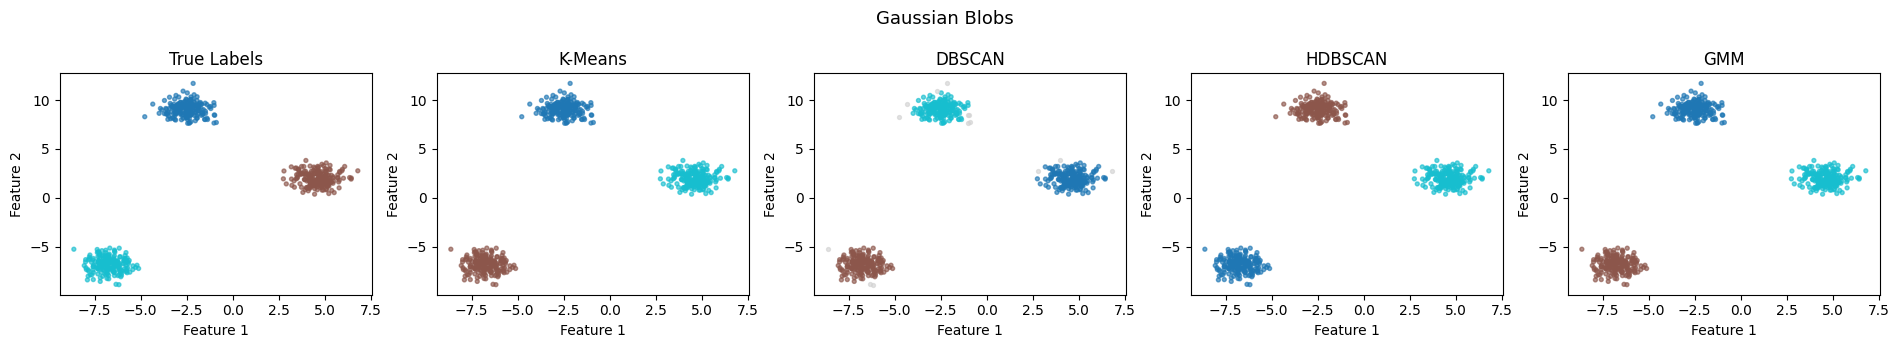


Two Moons: 600 observations × 2 features


,Dataset,Algorithm,ARI,NMI,Silhouette,DBI,Clusters,Noise (%),Runtime (s)
0,Two Moons,K-Means,0.2421,0.1835,0.4903,0.7788,2,0.0000,0.0298
1,Two Moons,DBSCAN,0.0000,0.0000,NaN,NaN,1,0.0000,0.0030
2,Two Moons,HDBSCAN,0.9900,0.9760,0.3350,1.1484,2,0.1667,0.0083
3,Two Moons,GMM,0.4891,0.3902,0.4676,0.8246,2,0.0000,0.0248


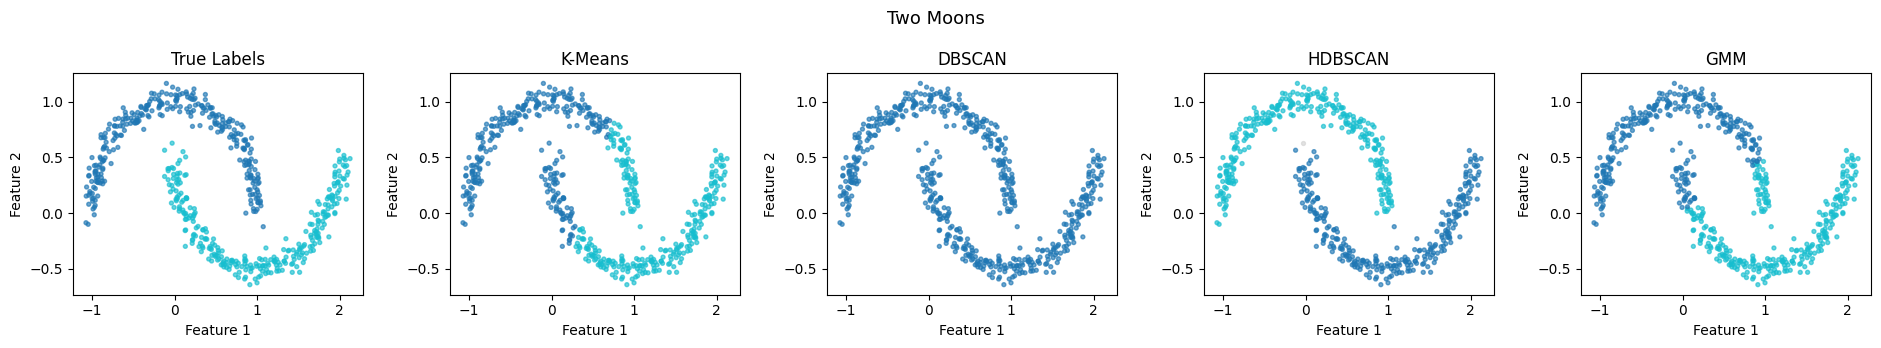


Concentric Circles: 600 observations × 2 features


,Dataset,Algorithm,ARI,NMI,Silhouette,DBI,Clusters,Noise (%),Runtime (s)
0,Concentric Circles,K-Means,-0.0016,0.0000,0.3426,1.2006,2,0.0,0.0318
1,Concentric Circles,DBSCAN,1.0000,1.0000,0.1368,1503.7142,2,0.0,0.0039
2,Concentric Circles,HDBSCAN,1.0000,1.0000,0.1368,1503.7142,2,0.0,0.0081
3,Concentric Circles,GMM,-0.0014,0.0002,0.3407,1.2044,2,0.0,0.0227


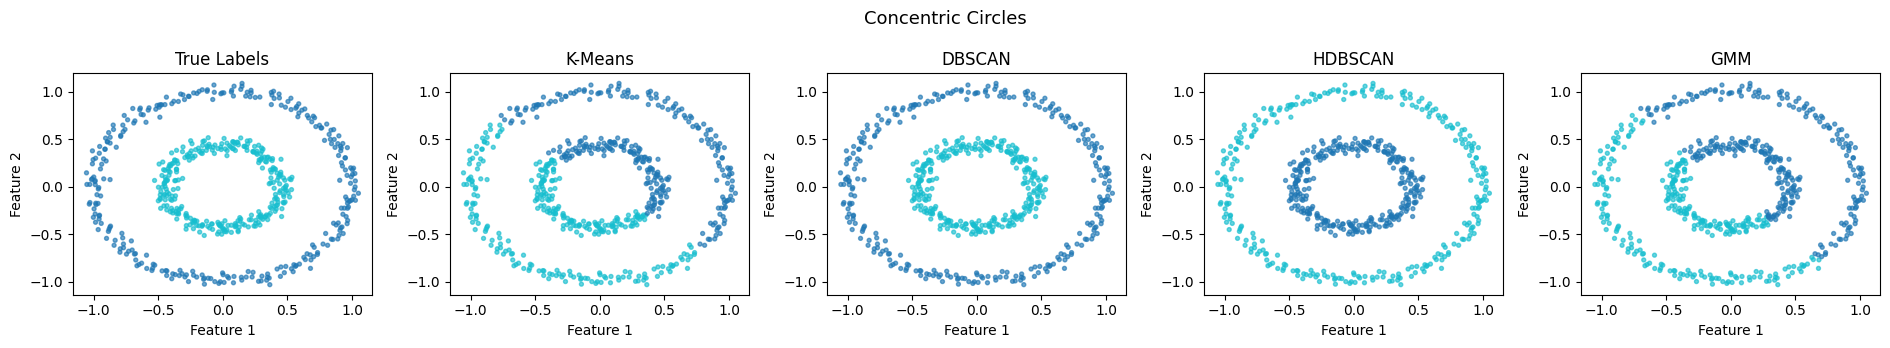


Varying Density: 600 observations × 2 features


,Dataset,Algorithm,ARI,NMI,Silhouette,DBI,Clusters,Noise (%),Runtime (s)
0,Varying Density,K-Means,0.9950,0.9904,0.7381,0.3833,3,0.0000,0.0279
1,Varying Density,DBSCAN,0.8621,0.8565,0.5788,0.6337,6,7.3333,0.0032
2,Varying Density,HDBSCAN,0.9950,0.9916,0.7411,0.3786,3,0.3333,0.0079
3,Varying Density,GMM,0.9950,0.9904,0.7362,0.3833,3,0.0000,0.0197


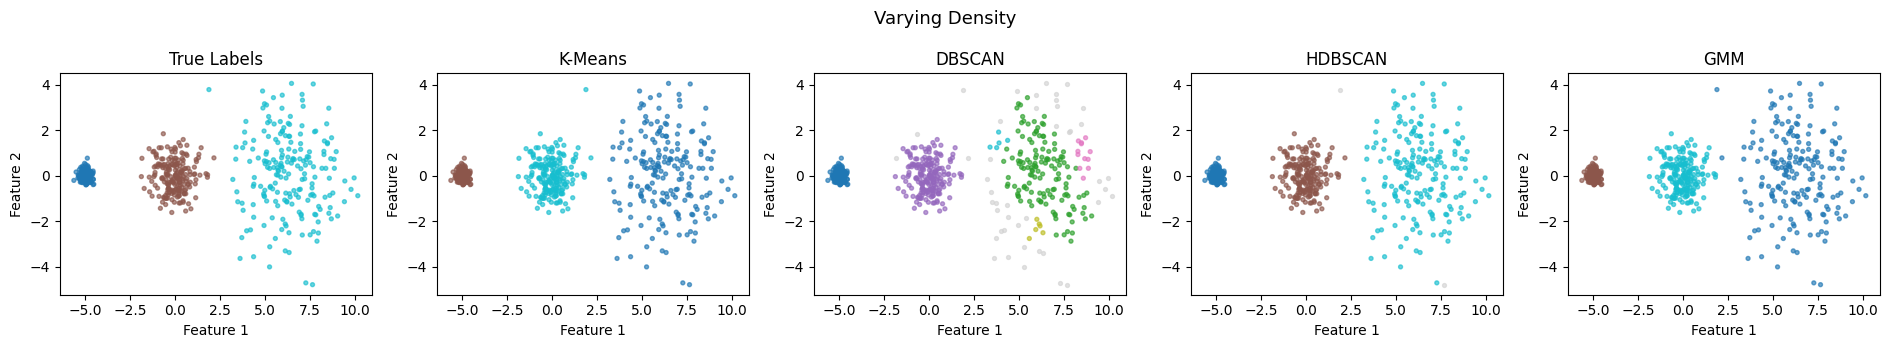


Elliptical Gaussian: 600 observations × 2 features


,Dataset,Algorithm,ARI,NMI,Silhouette,DBI,Clusters,Noise (%),Runtime (s)
0,Elliptical Gaussian,K-Means,0.8319,0.8108,0.6217,0.4995,3,0.0000,0.0357
1,Elliptical Gaussian,DBSCAN,0.8411,0.7958,0.3209,0.5677,6,5.6667,0.0047
2,Elliptical Gaussian,HDBSCAN,0.8277,0.7919,0.6453,0.4664,3,9.3333,0.0145
3,Elliptical Gaussian,GMM,0.9801,0.9660,0.5952,0.5275,3,0.0000,0.0256


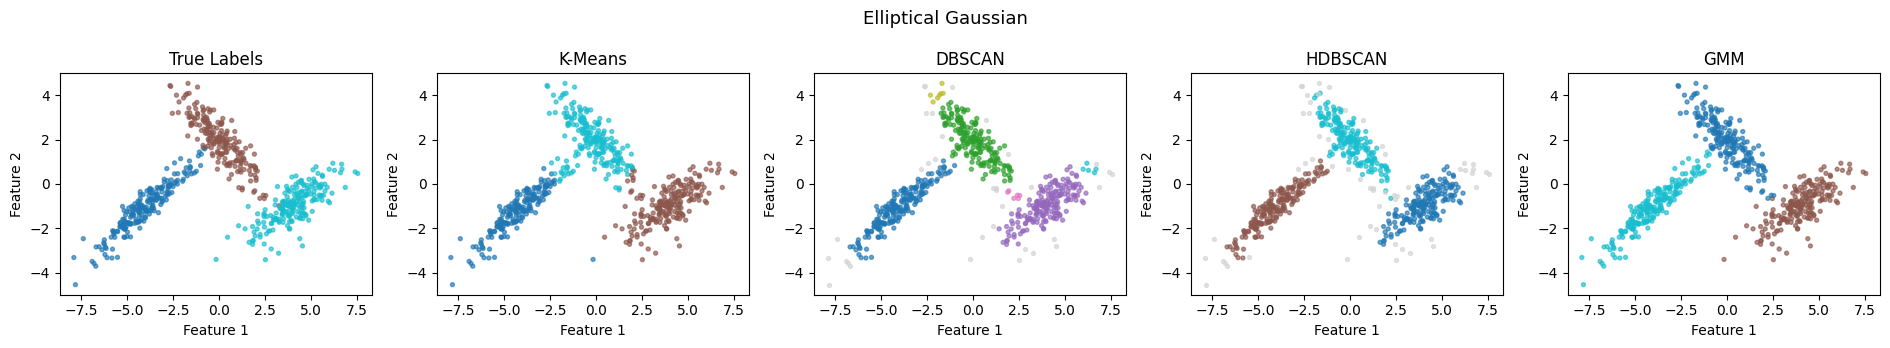

In [32]:

# Gaussian Blobs, Two Moons and Concentric Circles
synthetic = {
    'Gaussian Blobs': make_blobs(
        n_samples=600, centers=3,
        cluster_std=.70, random_state=RANDOM_STATE
    ),
    'Two Moons': make_moons(
        n_samples=600, noise=.06,
        random_state=RANDOM_STATE
    ),
    'Concentric Circles': make_circles(
        n_samples=600, factor=.45,
        noise=.04, random_state=RANDOM_STATE
    ),
}


# Varying Density dataset
X_density, y_density = make_blobs(
    n_samples=[200, 200, 200],
    centers=[[-5, 0], [0, 0], [6, 0]],
    cluster_std=[.20, .70, 1.65],
    random_state=RANDOM_STATE
)

synthetic['Varying Density'] = (X_density, y_density)


# Elliptical Gaussian dataset
rng = np.random.default_rng(RANDOM_STATE)

means = [(-4, -1), (0, 2), (4, -1)]

covariances = [
    np.array([[2.0, 1.5], [1.5, 1.3]]),
    np.array([[1.4, -1.0], [-1.0, 1.0]]),
    np.array([[1.6, .95], [.95, .9]])
]

X_elliptical = np.vstack([
    rng.multivariate_normal(m, c, size=200)
    for m, c in zip(means, covariances)
])

y_elliptical = np.repeat(np.arange(3), 200)

synthetic['Elliptical Gaussian'] = (
    X_elliptical, y_elliptical
)


# Algorithm parameters for synthetic datasets
synthetic_settings = {
    'Gaussian Blobs': dict(k=3, eps=.50),
    'Two Moons': dict(k=2, eps=.20),
    'Concentric Circles': dict(k=2, eps=.15),
    'Varying Density': dict(k=3, eps=.55, min_size=20),
    'Elliptical Gaussian': dict(k=3, eps=.45, min_size=20),
}


# Run clustering experiments
synthetic_tables = []

for name, (X, y) in synthetic.items():

    table, _ = show_experiment(
        name, X, y,
        **synthetic_settings[name]
    )

    synthetic_tables.append(table)
    all_tables.append(table)

synthetic_results = pd.concat(
    synthetic_tables,
    ignore_index=True
)


### Synthetic Dataset Analysis

The five synthetic datasets demonstrate how cluster geometry, density variation, and covariance structure influence the performance of different clustering algorithms.

**1. Gaussian Blobs**

K-Means, HDBSCAN, and GMM achieved perfect clustering agreement (**ARI = 1.0000, NMI = 1.0000**), correctly identifying all three clusters. DBSCAN also performed well (ARI = 0.9648), although it classified 2.33% of observations as noise.

The visualizations confirm that all four algorithms successfully identified the compact, well-separated groups. This suggests that simple cluster structures can be effectively handled by both centroid-based, probabilistic, and density-based approaches.

**2. Two Moons**

HDBSCAN achieved the strongest performance (**ARI = 0.9900, NMI = 0.9760**), successfully recovering the two curved clusters with only 0.17% noise.

In comparison, K-Means (ARI = 0.2421) and GMM (ARI = 0.4891) incorrectly divided portions of the interlocking moons. DBSCAN identified only one cluster (ARI = 0.0000), indicating that its fixed neighborhood radius was unsuitable for this configuration.

Interestingly, K-Means achieved a higher Silhouette Score (0.4903) than HDBSCAN (0.3350), despite producing substantially less accurate clusters. This illustrates how internal metrics may favor compact partitions rather than correctly identifying non-convex structures.

**3. Concentric Circles**

DBSCAN and HDBSCAN perfectly recovered the two concentric rings (**ARI = 1.0000, NMI = 1.0000**), whereas K-Means and GMM produced almost no agreement with the true labels (ARI ≈ 0).

The visualizations show that K-Means and GMM divided the circles into spatial sections rather than separating the inner and outer rings.

Despite achieving perfect clustering agreement, DBSCAN and HDBSCAN recorded extremely high DBI values (1503.7142). This occurs because the two correctly identified rings have nearly identical centroids, causing the centroid-separation component of DBI to become very small.

Therefore, DBI and Silhouette Score are not reliable indicators of clustering accuracy for this particular non-convex structure.

**4. Varying Density**

K-Means, HDBSCAN, and GMM achieved almost perfect clustering agreement (ARI = 0.9950), correctly identifying the three groups despite their different densities.

DBSCAN performed less effectively (ARI = 0.8621), identifying six clusters instead of three and classifying 7.33% of observations as noise. The visualization shows that the sparsest group was fragmented into smaller clusters.

HDBSCAN achieved the highest NMI (0.9916) and Silhouette Score (0.7411), demonstrating its ability to accommodate density differences in this experiment.

These results highlight the limitations of using a single fixed neighborhood radius in DBSCAN, although sufficiently separated clusters can still be identified effectively by K-Means and GMM.

**5. Elliptical Gaussian Clusters**

GMM achieved the strongest external clustering performance (**ARI = 0.9801, NMI = 0.9660**), outperforming K-Means (ARI = 0.8319), DBSCAN (ARI = 0.8411), and HDBSCAN (ARI = 0.8277).

The visualizations show that GMM successfully followed the elongated cluster distributions, while K-Means misclassified observations near the boundaries of the elliptical groups.

DBSCAN identified six clusters and classified 5.67% of observations as noise. HDBSCAN recovered three clusters but classified 9.33% as noise.

Although HDBSCAN achieved the highest Silhouette Score (0.6453), GMM provided substantially better agreement with the ground-truth labels. This demonstrates the advantage of GMM's full covariance modeling when clusters follow elongated Gaussian distributions.

### Overall Findings

The synthetic experiments reveal that **no single clustering algorithm performs best across all data structures**.

- **K-Means:** Performs strongly on compact, well-separated clusters but struggles with non-convex structures.
- **DBSCAN:** Can identify non-convex clusters but is sensitive to its neighborhood radius, particularly when densities vary.
- **HDBSCAN:** Performs strongly on non-convex and varying-density structures, although it may classify some observations as noise.
- **GMM:** Performs particularly well on elliptical Gaussian clusters because it models cluster covariance.

Importantly, Silhouette Score and DBI do not always agree with external metrics such as ARI and NMI. This is especially evident for Concentric Circles, where the density-based algorithms perfectly recovered the true clusters despite receiving unfavorable internal evaluation scores.

Consequently, clustering performance should be interpreted using a combination of quantitative metrics and visual examination rather than relying on a single evaluation measure.

## 3. Dry Bean Dataset

The **UCI Dry Bean dataset** contains 16 numerical features describing the physical characteristics of dry beans, with seven known bean varieties.

Unlike synthetic datasets, the Dry Bean dataset provides an opportunity to evaluate clustering algorithms on real-world observations, where different classes may exhibit overlapping feature distributions.

All 16 features are standardized using `StandardScaler` before applying K-Means, DBSCAN, HDBSCAN, and GMM.

**Principal Component Analysis (PCA)** is used only to reduce the data to two dimensions for visualization. All four algorithms are fitted using the complete 16-dimensional standardized dataset.

Clustering performance is evaluated using ARI, NMI, Silhouette Score, and DBI, followed by a comparison of the predicted clusters against the known bean varieties.


Dry Bean: 13,611 observations × 16 features


,Dataset,Algorithm,ARI,NMI,Silhouette,DBI,Clusters,Noise (%),Runtime (s)
0,Dry Bean,K-Means,0.6687,0.7138,0.3083,1.0993,7,0.0000,0.1275
1,Dry Bean,DBSCAN,0.0402,0.1397,0.2462,0.6809,6,6.2523,0.1873
2,Dry Bean,HDBSCAN,0.0344,0.1514,0.5747,0.5223,2,2.2776,1.0084
3,Dry Bean,GMM,0.6931,0.7428,0.2887,1.6288,7,0.0000,1.4509


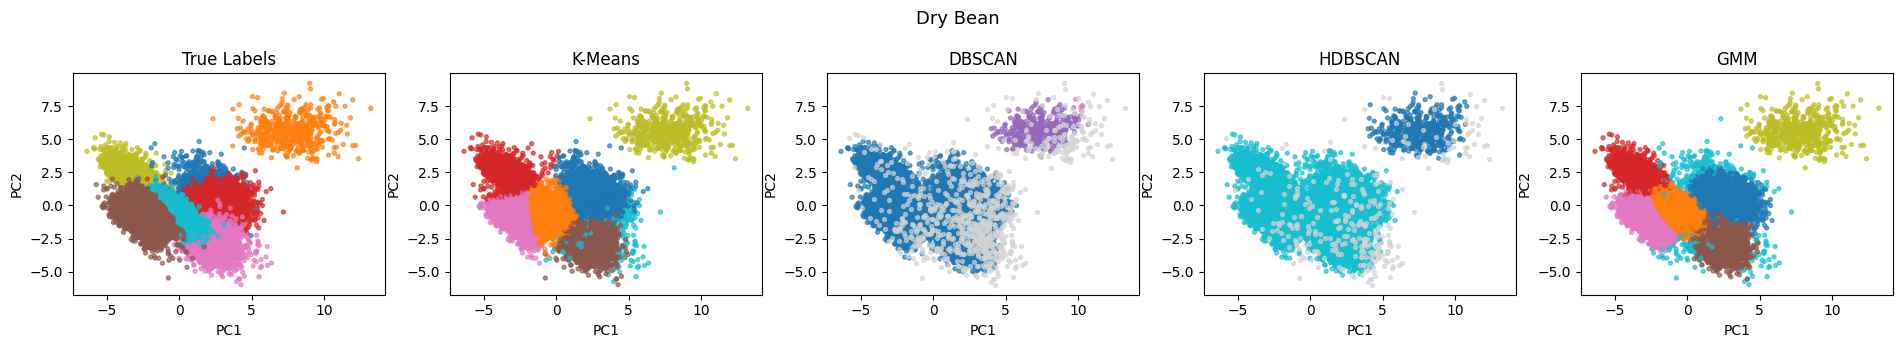

In [33]:

# Load and preprocess Dry Bean dataset
from ucimlrepo import fetch_ucirepo

bean = fetch_ucirepo(id=602)
X_dry = StandardScaler().fit_transform(bean.data.features)
y_dry = LabelEncoder().fit_transform(bean.data.targets.squeeze().to_numpy())


# Run clustering experiments
dry_results, dry_predictions = show_experiment(
    'Dry Bean', X_dry, y_dry, k=7, eps=.9502,
    min_size=20, min_samples=5
)

all_tables.append(dry_results)


### Dry Bean Dataset Analysis

The Dry Bean dataset contains **13,611 observations with 16 numerical features**, representing seven bean varieties. The results demonstrate differences in how the four clustering algorithms handle real-world, high-dimensional data.

**1. K-Means and GMM**

GMM achieved the highest external evaluation scores (**ARI = 0.6931, NMI = 0.7428**), slightly outperforming K-Means (ARI = 0.6687, NMI = 0.7138). Both algorithms identified seven clusters without classifying any observations as noise.

The PCA visualizations show that both methods separated several bean varieties reasonably well, although some clusters overlap. GMM's improvement suggests that modeling cluster covariance provides an advantage over K-Means' centroid-based approach for this dataset.

**2. DBSCAN and HDBSCAN**

DBSCAN achieved relatively low agreement with the known bean varieties (**ARI = 0.0402, NMI = 0.1397**), identifying six clusters and classifying 6.25% of observations as noise.

HDBSCAN performed similarly in external agreement (ARI = 0.0344, NMI = 0.1514), identifying only two clusters and classifying 2.28% of observations as noise.

The visualizations show that both density-based methods grouped several bean varieties into large clusters rather than distinguishing all seven classes. This suggests that the density structures identified under the selected parameters do not closely correspond to the known bean varieties.

**3. Internal and External Metric Comparison**

HDBSCAN achieved the highest Silhouette Score (**0.5747**) and lowest DBI (**0.5223**), despite having the lowest ARI among the four algorithms.

In contrast, GMM achieved the highest ARI and NMI but recorded a lower Silhouette Score (0.2887) and higher DBI (1.6288).

This difference highlights that internal metrics measure cluster cohesion and separation rather than agreement with known class labels. HDBSCAN's two broad clusters may appear more compact and separated according to these metrics, even though they do not represent the seven bean varieties accurately.

### Key Finding

**GMM achieved the strongest agreement with the known bean varieties**, followed closely by K-Means. DBSCAN and HDBSCAN performed substantially worse under the tested configurations.

The results suggest that partitioning the observations into seven clusters is more effective for recovering the known varieties than the density-based partitions obtained here.

However, the two-dimensional PCA visualizations are projections of the original 16-dimensional data and should not be interpreted as exact representations of the clustering boundaries.

## 4. Wholesale Customers Dataset

The **UCI Wholesale Customers dataset** contains 440 observations with six numerical features representing annual spending across different product categories.

Unlike the Dry Bean dataset, which contains seven known varieties, the Wholesale Customers dataset uses **Channel** (Horeca or Retail) as the reference label for evaluating whether the clustering algorithms can identify differences in customer purchasing behavior.

The six spending features are standardized using `StandardScaler`, without applying a logarithmic transformation. The `Channel` attribute is excluded from the clustering features to prevent information leakage.

K-Means, DBSCAN, HDBSCAN, and GMM are applied to the six-dimensional standardized dataset. PCA is used only for two-dimensional visualization.

Clustering performance is evaluated using ARI, NMI, Silhouette Score, and DBI, followed by an interpretation of the predicted customer groups.


Wholesale Customers: 440 observations × 6 features


,Dataset,Algorithm,ARI,NMI,Silhouette,DBI,Clusters,Noise (%),Runtime (s)
0,Wholesale Customers,K-Means,0.2352,0.1979,0.5472,1.1318,2,0.0000,0.0295
1,Wholesale Customers,DBSCAN,0.1312,0.0728,0.3794,0.5378,3,29.7727,0.0048
2,Wholesale Customers,HDBSCAN,0.2082,0.2164,0.3896,0.8756,2,49.7727,0.0085
3,Wholesale Customers,GMM,0.0956,0.0378,0.4497,1.9077,2,0.0000,0.0498


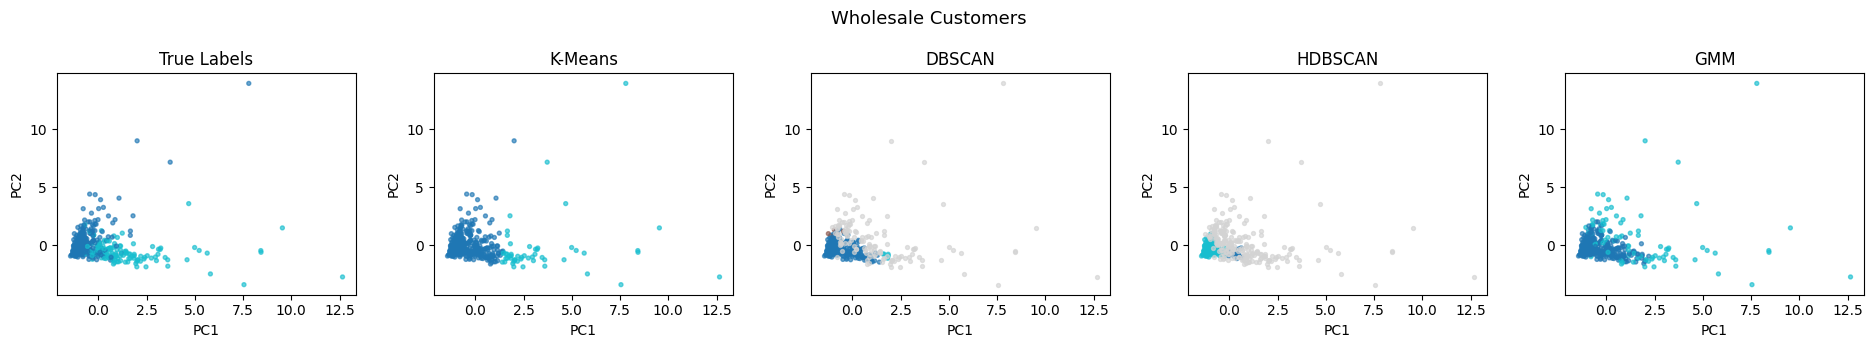

In [34]:
wholesale_url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/00292/Wholesale%20customers%20data.csv'
wholesale = pd.read_csv(wholesale_url)
features = ['Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']
X_wholesale = StandardScaler().fit_transform(wholesale[features])
y_wholesale = wholesale['Channel'].to_numpy()

wholesale_results, wholesale_predictions = show_experiment(
    'Wholesale Customers', X_wholesale, y_wholesale,
    k=2, eps=.5968, min_size=20, min_samples=1)
all_tables.append(wholesale_results)

### Wholesale Customers Dataset Analysis

The Wholesale Customers dataset contains **440 observations with six numerical spending features**. The `Channel` attribute is used as the reference label to evaluate whether the clustering algorithms can distinguish between Horeca and Retail customers.

**1. K-Means and GMM**

K-Means achieved the highest ARI (**0.2352**) and Silhouette Score (**0.5472**), identifying two clusters without classifying any observations as noise. Its NMI of 0.1979 indicates relatively weak agreement with the reference channels.

GMM performed worse, achieving an ARI of 0.0956 and NMI of 0.0378. Although GMM also identified two clusters without noise, its lower external scores suggest that Gaussian covariance modeling did not improve agreement with the customer channels in this experiment.

The PCA visualizations show substantial overlap between the two reference channels, which helps explain why both algorithms struggled to distinguish them accurately.

**2. DBSCAN and HDBSCAN**

DBSCAN achieved an ARI of 0.1312 and NMI of 0.0728, identifying three clusters while classifying **29.77% of observations as noise**.

HDBSCAN achieved an ARI of 0.2082 and the highest NMI (**0.2164**), identifying two clusters but classifying **49.77% of observations as noise**.

The visualizations show that both density-based methods classified many observations outside the densest regions as noise. This indicates that the selected density thresholds were restrictive for the observed spending distributions.

Although HDBSCAN achieved slightly higher NMI than K-Means, its large noise percentage limits its usefulness if the objective is to assign every customer to a segment.

**3. Internal and External Metric Comparison**

K-Means achieved the highest Silhouette Score (0.5472), suggesting relatively compact and separated clusters under this metric.

DBSCAN recorded the lowest DBI (0.5378), despite having lower ARI and NMI than K-Means. However, its internal metrics were calculated only on the non-noise observations, excluding approximately 30% of the dataset.

Similarly, HDBSCAN's internal metrics exclude almost half of the observations. Therefore, these scores should not be compared without considering the different proportions of data retained.

### Key Finding

**K-Means provided the strongest overall result for recovering the reference channels under the tested configurations**, achieving the highest ARI and Silhouette Score while assigning all observations to clusters.

However, all four algorithms demonstrated relatively weak agreement with the known channels. This suggests that differences in purchasing behavior may not correspond directly to the Horeca and Retail classifications.

The PCA visualization also reveals a concentrated group of customers alongside widely dispersed observations and extreme spending values, indicating that the dataset has an uneven distribution.

Consequently, the results should not be interpreted as evidence that the clustering algorithms failed to identify meaningful customer segments

## 5. Human Activity Recognition (HAR) Dataset

The **UCI Human Activity Recognition Using Smartphones (HAR) dataset** contains 10,299 observations, 561 engineered sensor features, and six activity labels representing different human movements and postures.

This dataset provides an opportunity to evaluate how K-Means, DBSCAN, HDBSCAN, and GMM perform on high-dimensional sensor data, where activity classes may exhibit overlapping feature patterns.

### Data Preparation

To maintain a practical computational runtime, a **stratified sample of 2,400 observations** is selected from the combined official training and test sets, preserving the relative proportions of the six activity classes.

The features are standardized using `StandardScaler` before applying PCA to reduce the dimensionality from 561 features to **20 principal components**.

Unlike the Dry Bean and Wholesale Customers experiments, **all four clustering algorithms are fitted using the 20-dimensional PCA representation**, rather than the complete feature set.

An additional two-dimensional PCA projection is used solely for visualizing the clustering results.

### Experimental Limitations

The reduced sample size and dimensionality may affect the clustering structures identified by the algorithms. Therefore, the results represent performance on the selected sample and PCA-transformed features, rather than a full-dataset benchmark.

The dataset is downloaded from the official UCI repository and cached locally for subsequent runs. An internet connection is required for the initial download.

HAR sample: (2400, 20) | Activity classes: 6
PCA explained variance: 0.7734

Human Activity Recognition: 2,400 observations × 20 features


,Dataset,Algorithm,ARI,NMI,Silhouette,DBI,Clusters,Noise (%),Runtime (s)
0,Human Activity Recognition,K-Means,0.4313,0.5686,0.2191,1.5598,6,0.0,0.0436
1,Human Activity Recognition,DBSCAN,0.0219,0.1821,0.0820,1.2039,7,82.5,0.0117
2,Human Activity Recognition,HDBSCAN,0.3181,0.4760,0.5406,0.7531,2,18.5,0.1116
3,Human Activity Recognition,GMM,0.4325,0.5806,0.2011,1.7136,6,0.0,0.2175


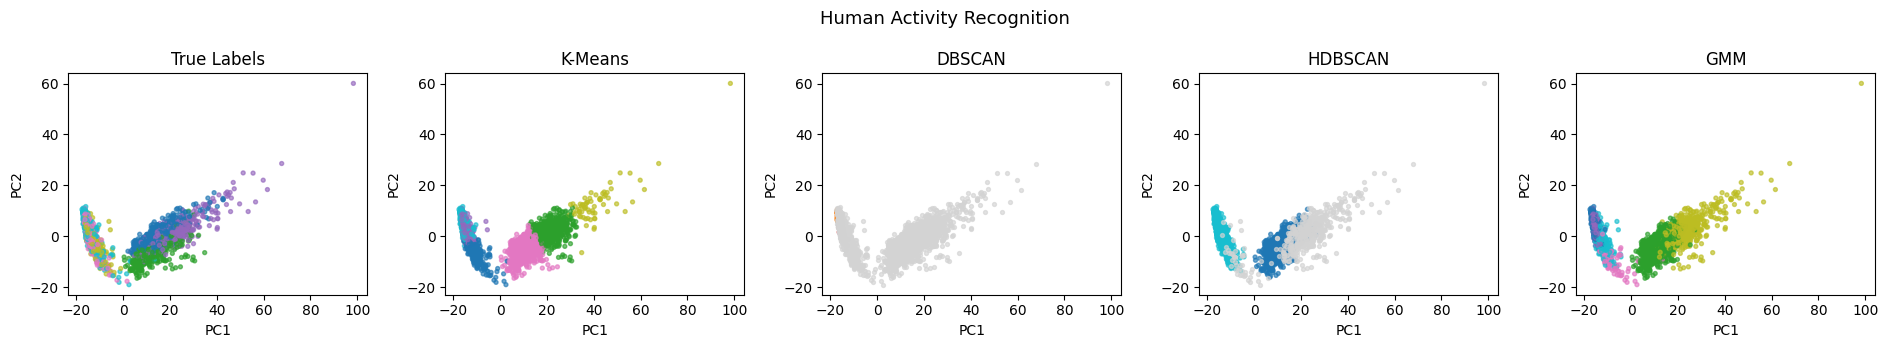

In [35]:

# Download and cache HAR dataset
har_url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/00240/UCI%20HAR%20Dataset.zip'

cache_dir = Path('clustering_data')
cache_dir.mkdir(exist_ok=True)

har_zip = cache_dir / 'UCI_HAR_Dataset.zip'

if not har_zip.exists():
    print('Downloading UCI HAR dataset (one-time download)...')
    urllib.request.urlretrieve(har_url, har_zip)


# Load training and test data
with zipfile.ZipFile(har_zip) as z:

    def read_har(split, filename):
        path = f'UCI HAR Dataset/{split}/{filename}'

        with z.open(path) as f:
            return np.loadtxt(
                f,
                dtype=np.float32 if filename.startswith('X_') else np.int32
            )

    X_har_full = np.vstack([
        read_har('train', 'X_train.txt'),
        read_har('test', 'X_test.txt')
    ])

    y_har_full = np.concatenate([
        read_har('train', 'y_train.txt'),
        read_har('test', 'y_test.txt')
    ])


# Stratified sampling
_, X_har_sample, _, y_har = train_test_split(
    X_har_full,
    y_har_full,
    test_size=2400,
    stratify=y_har_full,
    random_state=RANDOM_STATE
)


# Standardization and PCA
X_har_scaled = StandardScaler().fit_transform(X_har_sample)

pca_har = PCA(
    n_components=20,
    random_state=RANDOM_STATE
)

X_har = pca_har.fit_transform(X_har_scaled)

print('HAR sample:', X_har.shape, '| Activity classes:', len(np.unique(y_har)))
print('PCA explained variance:', round(pca_har.explained_variance_ratio_.sum(), 4))


# Run clustering experiments
har_results, har_predictions = show_experiment(
    'Human Activity Recognition',
    X_har,
    y_har,
    k=6,
    eps=4.0,
    min_size=35,
    min_samples=10
)

all_tables.append(har_results)


### Human Activity Recognition Dataset Analysis

The HAR experiment uses **2,400 stratified observations reduced from 561 features to 20 principal components**, retaining approximately **77.34% of the original standardized variance**. The results demonstrate how the four clustering algorithms perform when identifying six human activities from high-dimensional sensor data.

**1. K-Means and GMM**

GMM achieved the highest external evaluation scores (**ARI = 0.4325, NMI = 0.5806**), closely followed by K-Means (ARI = 0.4313, NMI = 0.5686).

Both algorithms identified six clusters without classifying any observations as noise. However, their moderate ARI values indicate that the predicted clusters do not perfectly correspond to the six known activities.

The PCA visualizations show considerable overlap between several activity classes, suggesting that some activities exhibit similar sensor patterns. Nevertheless, K-Means and GMM recovered more of the reference class structure than the density-based algorithms under the tested configurations.

**2. DBSCAN and HDBSCAN**

DBSCAN performed poorly in terms of external agreement (**ARI = 0.0219, NMI = 0.1821**), identifying seven clusters and classifying **82.5% of observations as noise**.

The visualization confirms that most observations were excluded from its predicted clusters. This suggests that the fixed neighborhood radius (`eps = 4.0`) was too restrictive for much of the 20-dimensional representation.

HDBSCAN performed better (ARI = 0.3181, NMI = 0.4760), identifying two clusters while classifying **18.5% of observations as noise**.

Although HDBSCAN identified fewer clusters than the six known activities, it captured broader groupings within the data. However, these groups did not fully correspond to the reference activity labels.

**3. Internal and External Metric Comparison**

HDBSCAN achieved the highest Silhouette Score (**0.5406**) and lowest DBI (**0.7531**), indicating relatively compact and separated clusters among its non-noise observations.

In contrast, GMM achieved a lower Silhouette Score

## 6. Final Comparison and Conclusion

This section consolidates the results of **four clustering algorithms across eight individual datasets**, producing a total of **32 experimental results**.

The comparison considers four evaluation metrics:

- **ARI and NMI:** Measure agreement between predicted clusters and reference labels.
- **Silhouette Score and DBI:** Evaluate internal cluster cohesion and separation.

These metrics assess different aspects of clustering performance and may produce conflicting conclusions, particularly for non-convex clusters or algorithms that classify observations as noise.

Rather than averaging evaluation scores across datasets to identify a universal winner, the analysis focuses on **how the assumptions of each clustering algorithm align with the characteristics of different datasets**.

The final comparison highlights the strengths, limitations, and suitable applications of K-Means, DBSCAN, HDBSCAN, and GMM.

In [36]:

# Combine results from all datasets
final_results = pd.concat(all_tables, ignore_index=True)

assert len(final_results) == 32, (
    f'Expected 32 algorithm-dataset rows, found {len(final_results)}'
)

display(final_results.round(4))


# Identify highest ARI for each dataset
print('\nHighest ARI within each dataset:')

best_idx = final_results.groupby('Dataset')['ARI'].idxmax()

display(
    final_results.loc[
        best_idx,
        ['Dataset', 'Algorithm', 'ARI', 'NMI', 'Clusters', 'Noise (%)']
    ].reset_index(drop=True).round(4)
)


# Export results to CSV
final_results.to_csv(
    'clustering_comparison_4_algorithms_8_datasets.csv',
    index=False
)


,Dataset,Algorithm,ARI,NMI,Silhouette,DBI,Clusters,Noise (%),Runtime (s)
0,Gaussian Blobs,K-Means,1.0000,1.0000,0.8903,0.1549,3,0.0000,0.0316
1,Gaussian Blobs,DBSCAN,0.9648,0.9427,0.8950,0.1492,3,2.3333,0.0035
2,Gaussian Blobs,HDBSCAN,1.0000,1.0000,0.8903,0.1549,3,0.0000,0.0083
3,Gaussian Blobs,GMM,1.0000,1.0000,0.8903,0.1549,3,0.0000,0.0209
4,Two Moons,K-Means,0.2421,0.1835,0.4903,0.7788,2,0.0000,0.0298
5,Two Moons,DBSCAN,0.0000,0.0000,NaN,NaN,1,0.0000,0.0030
6,Two Moons,HDBSCAN,0.9900,0.9760,0.3350,1.1484,2,0.1667,0.0083
7,Two Moons,GMM,0.4891,0.3902,0.4676,0.8246,2,0.0000,0.0248
8,Concentric Circles,K-Means,-0.0016,0.0000,0.3426,1.2006,2,0.0000,0.0318
9,Concentric Circles,DBSCAN,1.0000,1.0000,0.1368,1503.7142,2,0.0000,0.0039



Highest ARI within each dataset:


,Dataset,Algorithm,ARI,NMI,Clusters,Noise (%)
0,Concentric Circles,DBSCAN,1.0000,1.0000,2,0.0000
1,Dry Bean,GMM,0.6931,0.7428,7,0.0000
2,Elliptical Gaussian,GMM,0.9801,0.9660,3,0.0000
3,Gaussian Blobs,K-Means,1.0000,1.0000,3,0.0000
4,Human Activity Recognition,GMM,0.4325,0.5806,6,0.0000
5,Two Moons,HDBSCAN,0.9900,0.9760,2,0.1667
6,Varying Density,HDBSCAN,0.9950,0.9916,3,0.3333
7,Wholesale Customers,K-Means,0.2352,0.1979,2,0.0000


### Final Interpretation and Limitations

This study compared **K-Means, DBSCAN, HDBSCAN, and Gaussian Mixture Models (GMM)** across five synthetic and three real-world datasets, using ARI, NMI, Silhouette Score, and Davies–Bouldin Index (DBI).

The findings demonstrate that clustering performance depends strongly on the underlying data structure and the assumptions of each algorithm.

#### 1. Comparison of Algorithm Performance

**K-Means — Compact and Well-Separated Clusters**

K-Means performed particularly well on Gaussian Blobs (ARI = 1.0000) and Varying Density (ARI = 0.9950). It also achieved the highest ARI on Wholesale Customers (0.2352).

However, its performance declined considerably on non-convex structures, particularly Concentric Circles (ARI = -0.0016) and Two Moons (ARI = 0.2421).

These findings suggest that K-Means is effective when clusters are relatively compact and spatially separated, but less suitable for irregular or nested cluster structures.

**DBSCAN — Non-Convex Clusters and Parameter Sensitivity**

DBSCAN perfectly recovered Concentric Circles (ARI = 1.0000), demonstrating its ability to identify non-convex clusters.

However, its performance was sensitive to the selected neighborhood radius. It merged Two Moons into one cluster (ARI = 0.0000) and fragmented Varying Density into six clusters instead of three.

On HAR, DBSCAN classified 82.5% of observations as noise, resulting in very low external agreement (ARI = 0.0219).

These findings demonstrate that DBSCAN can recover complex cluster geometry but may struggle when a single neighborhood radius does not adequately represent the dataset's density structure.

**HDBSCAN — Non-Convex Geometry and Varying Density**

HDBSCAN performed strongly on Two Moons (ARI = 0.9900), Concentric Circles (ARI = 1.0000), and Varying Density (ARI = 0.9950).

Unlike DBSCAN, HDBSCAN successfully recovered the two curved groups in Two Moons and the three groups in Varying Density under the selected configurations.

However, its performance on real-world datasets was less consistent. It identified only two clusters on Dry Bean (ARI = 0.0344) and classified 49.77% of Wholesale Customers as noise.

Therefore, HDBSCAN offers advantages for certain irregular or varying-density structures but does not necessarily recover known class labels in more complex real-world datasets.

**GMM — Covariance Modeling and Elliptical Clusters**

GMM achieved the highest ARI on Elliptical Gaussian (0.9801), Dry Bean (0.6931), and HAR (0.4325).

Its strong performance on Elliptical Gaussian demonstrates the advantage of modeling cluster covariance, allowing it to represent elongated Gaussian distributions more effectively than K-Means.

However, GMM performed poorly on Concentric Circles (ARI = -0.0014) and achieved relatively low agreement on Wholesale Customers (ARI = 0.0956).

These findings suggest that GMM is particularly effective when the data can be reasonably represented by Gaussian components, but it is not universally superior.

#### 2. External and Internal Metric Disagreement

The experiments demonstrate that internal evaluation metrics do not always reflect agreement with reference labels.

For example, DBSCAN and HDBSCAN perfectly recovered Concentric Circles (ARI = 1.0000), yet recorded extremely high DBI values (1503.7142). This occurs because the two concentric clusters have nearly identical centroids, making DBI unsuitable for evaluating this structure.

Similarly, HDBSCAN achieved the highest Silhouette Score on Dry Bean (0.5747) and HAR (0.5406), despite producing lower ARI and NMI than K-Means or GMM.

These findings demonstrate that **Silhouette Score and DBI favor particular geometric properties rather than agreement with known classes**.

Furthermore, internal metrics for DBSCAN and HDBSCAN were calculated only on non-noise observations. Therefore, noise percentages must be considered when comparing their scores against algorithms that assign every observation to a cluster.

#### 3. Experimental Limitations

Several limitations should be considered when interpreting the results:

- **Known class counts:** K-Means and GMM were provided with the number of reference classes, whereas DBSCAN and HDBSCAN determined cluster counts from density characteristics.
- **Hyperparameter selection:** Some density-based parameters were explored using ground-truth agreement, so the study does not represent a fully label-independent parameter selection process.
- **Reference labels:** Known classes may not correspond directly to natural clustering structures, particularly for Wholesale Customers and HAR.
- **Dimensionality reduction:** HAR was evaluated using 2,400 stratified observations and 20 PCA components, rather than the complete dataset and original feature space.
- **Evaluation and runtime:** Silhouette Score was estimated using up to 2,000 observations, and runtime measurements depend on the computational environment. The reported results reflect the selected datasets and parameter configurations rather than exhaustive optimization.

#### 4. Overall Conclusion

The results indicate that **no single clustering algorithm consistently outperforms the others across all eight datasets**.

K-Means is a strong baseline for compact, well-separated groups. DBSCAN and HDBSCAN are better suited to certain non-convex structures, with HDBSCAN demonstrating greater flexibility under varying density conditions. GMM provides advantages when clusters exhibit approximately Gaussian distributions with different covariance structures.

The real-world experiments further demonstrate that recovering known labels can be challenging even when algorithms identify geometrically meaningful clusters.

Ultimately, **the choice of clustering algorithm should be guided by dataset characteristics, clustering objectives, and the limitations of the evaluation metrics**, rather than selecting a universal winner based on a single score.